# EDA: анализ оттока клиентов телеком-компании

## Цель проекта

Исследовать факторы, связанные с оттоком клиентов, определить группы с повышенной долей оттока и сформулировать гипотезы для последующего построения модели прогнозирования.

## Бизнес-вопрос

Какие характеристики клиентов связаны с более высокой вероятностью оттока и какие клиентские сегменты требуют дополнительного исследования с точки зрения удержания?

## Этапы анализа

1. Проверка качества и структуры данных.
2. Исследование распределения целевой переменной.
3. Анализ числовых и категориальных признаков.
4. Сравнение оттока между клиентскими сегментами.
5. Проверка отдельных статистических гипотез.
6. Формулирование выводов, ограничений и следующих шагов для ML.

## Инструменты

Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite.

## Описание данных

Источник: SQLite-база 'data/processed/churn.db', таблица 'customers'.

Единица наблюдения - клиент телеком-компании.

В таблице представлены сведения о стаже клиента, платежах, типе договора, подключённых услугах и других характеристиках.

Целевая переменная - 'Churn':

- 'Yes' - клиент прекратил обслуживание;
- 'No' - клиент остался.

Перед анализом проверяются структура таблицы, типы данных, пропуски, дубликаты и корректность значений.

In [1]:
%matplotlib inline
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

## Загрузка данных

In [2]:
DB_PATH = Path("../data/processed/churn.db")
FIGURES_DIR = Path("../reports/figures")

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"База данных не найдена: {DB_PATH.resolve()}. "
        "Проверь рабочую директорию и путь к файлу."
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query(
        "SELECT * FROM customers",
        conn
    )

print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
display(df.head())

Количество строк: 7032
Количество столбцов: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

missing = df.isna().sum()
print("Столбцы с пропусками:")
display(missing[missing > 0])

print("Полных дубликатов:", df.duplicated().sum())
print(
    "Повторяющихся customerID:",
    df["customerID"].duplicated().sum()
)

display(df.describe().T)

for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}: {df[col].nunique()} уникальных значений")
    display(df[col].value_counts(dropna=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


Series([], dtype: int64)

Полных дубликатов: 0
Повторяющихся customerID: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,"7,032.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,"7,032.00",32.42,24.55,1.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,032.00",64.80,30.09,18.25,35.59,70.35,89.86,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"



customerID: 7032 уникальных значений


...

PaperlessBilling
Yes    4168
No     2864
Name: count, dtype: int64


PaymentMethod: 4 уникальных значений


PaymentMethod
Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: count, dtype: int64


Churn: 2 уникальных значений


Churn
No     5163
Yes    1869
Name: count, dtype: int64

## Результаты проверки качества данных

После загрузки таблица содержит 7 032 записи о клиентах и 21 столбец.

В загруженных данных пропуски не обнаружены. Типы данных соответствуют основным задачам анализа: числовые признаки представлены числовыми типами, категориальные — строковыми.

Проверены полные дубликаты строк и уникальность идентификатора `customerID`. Полных дубликатов не обнаружено, все значения customerID уникальны.
На этапе первичного анализа идентификатор `customerID` используется для идентификации клиента, но не рассматривается как содержательный признак для прогнозирования оттока.

,customers,share_pct
Churn,,
No,5163,73.42
Yes,1869,26.58


Доля ушедших клиентов: 26.58%


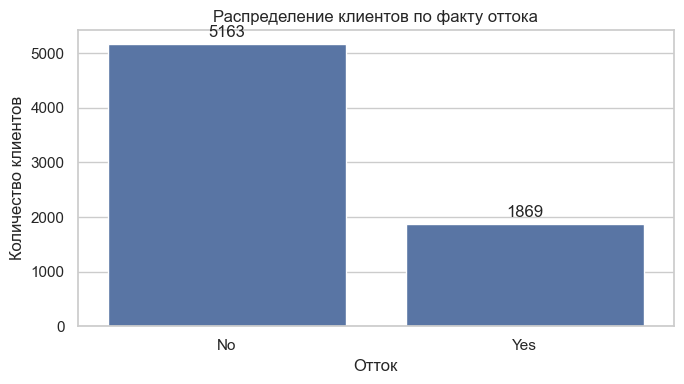

In [4]:
churn_counts = df["Churn"].value_counts()

churn_summary = pd.DataFrame({
    "customers": churn_counts,
    "share_pct": churn_counts / len(df) * 100
})
display(churn_summary.round(2))

churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"Доля ушедших клиентов: {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    color="#4C72B0",
    ax=ax
)
ax.set_title("Распределение клиентов по факту оттока")
ax.set_xlabel("Отток")
ax.set_ylabel("Количество клиентов")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "churn_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## Интерпретация целевой переменной

В выборке 1 869 ушедших клиентов из 7 032, что составляет 26,58%. Оставшиеся клиенты составляют 73,42%.

Таким образом, классы распределены неравномерно. При дальнейшем построении модели accuracy следует оценивать вместе с метриками, учитывающими качество обнаружения ушедших клиентов.

В качестве основных метрик для сравнения моделей можно рассмотреть precision, recall, F1-score и ROC-AUC. Выбор основной метрики зависит от цели прогнозирования и допустимого соотношения ложноположительных и ложноотрицательных прогнозов.

На этапе EDA не делается вывод о том, что использование `class_weight='balanced'` обязательно улучшит модель. Это вариант, который следует проверить экспериментально.

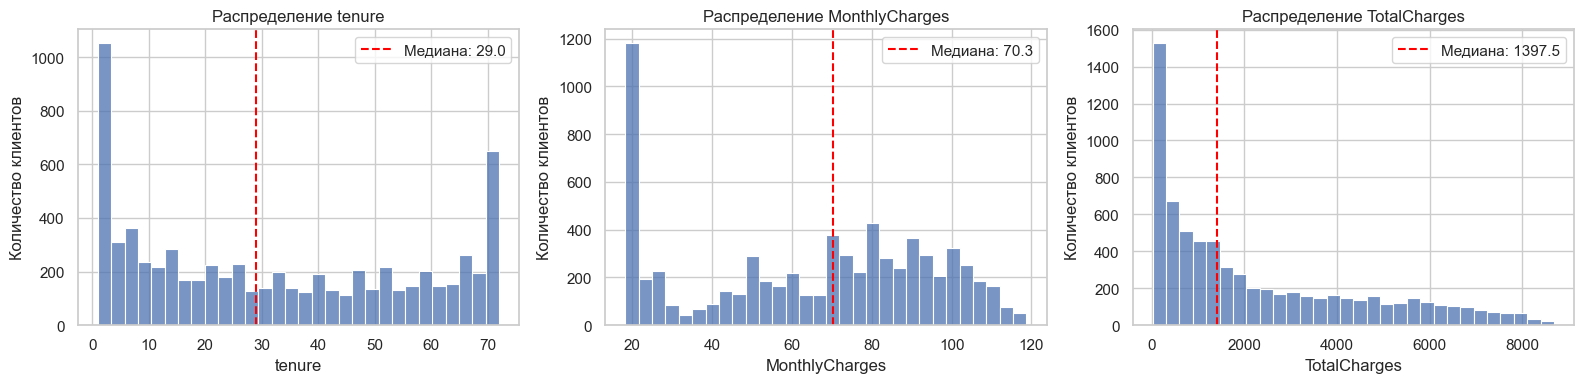

,mean,median,std,min,max,skewness
tenure,32.42,29.00,24.55,1.00,72.00,0.24
MonthlyCharges,64.80,70.35,30.09,18.25,118.75,-0.22
TotalCharges,"2,283.30","1,397.48","2,266.77",18.80,"8,684.80",0.96


In [5]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(num_cols, axes):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=False,
        ax=ax
    )
    median_value = df[col].median()
    ax.axvline(
        median_value,
        linestyle="--",
        color="red",
        label=f"Медиана: {median_value:.1f}"
    )
    ax.set_title(f"Распределение {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество клиентов")
    ax.legend()

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "numeric_distributions.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

distribution_summary = df[num_cols].agg(
    ["mean", "median", "std", "min", "max"]
).T
distribution_summary["skewness"] = df[num_cols].skew()
display(distribution_summary.round(2))

## Интерпретация числовых распределений

- `tenure`: распределение неоднородное, наблюдаются скопления клиентов с небольшим и большим стажем. Необходимо отдельно проверить, как доля оттока меняется с увеличением стажа.
- `MonthlyCharges`: распределение неоднородное, с выраженным скоплением клиентов в нижней части диапазона и дополнительными скоплениями в более высоких диапазонах.
- `TotalCharges`: распределение с длинным правым хвостом. Суммарные платежи связаны со стажем обслуживания и размером ежемесячной платы.

Форма распределений важна для интерпретации данных, но сама по себе не определяет выбор модели. Масштабирование, преобразования и создание дополнительных признаков должны оцениваться с учётом используемого алгоритма и результатов валидации.

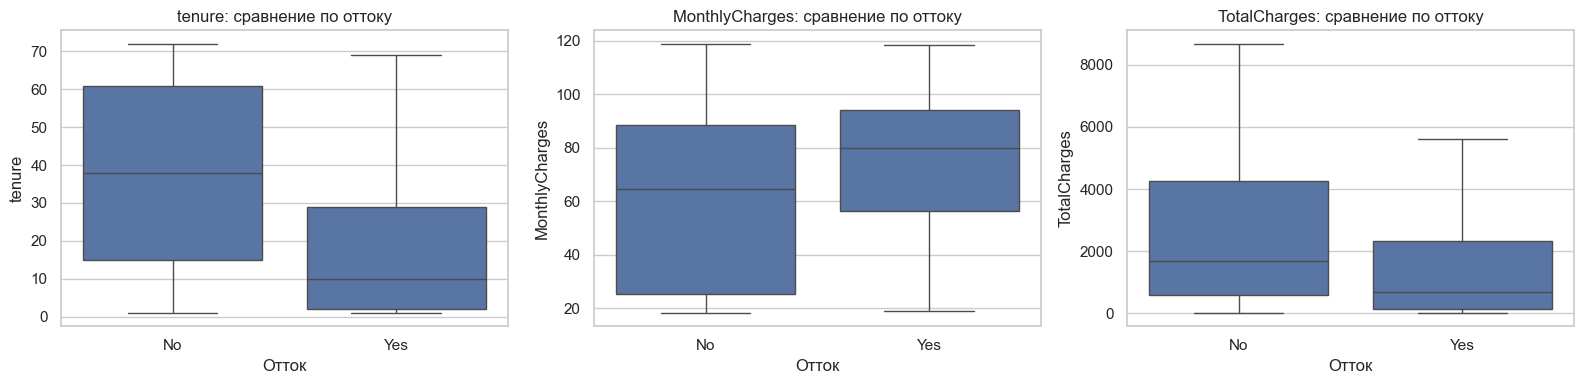

tenure                    MonthlyCharges                     \
       count median  mean   std          count median  mean   std   
Churn                                                               
No      5163  38.00 37.65 24.08           5163  64.45 61.31 31.09   
Yes     1869  10.00 17.98 19.53           1869  79.65 74.44 24.67   

      TotalCharges                             
             count   median     mean      std  
Churn                                          
No            5163 1,683.60 2,555.34 2,329.46  
Yes           1869   703.55 1,531.80 1,890.82

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(num_cols, axes):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        order=["No", "Yes"],
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{col}: сравнение по оттоку")
    ax.set_xlabel("Отток")
    ax.set_ylabel(col)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "numeric_by_churn.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

numeric_by_churn = (
    df.groupby("Churn")[num_cols]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)
display(numeric_by_churn)

## Сравнение числовых признаков по факту оттока

**Стаж обслуживания (`tenure`).** На boxplot у ушедших клиентов медиана стажа заметно ниже, чем у оставшихся. Это согласуется с гипотезой о повышенном риске оттока на ранних этапах обслуживания. Для количественной проверки необходимо рассчитать долю оттока в отдельных интервалах стажа.

**Ежемесячная плата (`MonthlyCharges`).** Медиана ежемесячной платы у ушедших клиентов выше, чем у оставшихся. Это указывает на различие распределений, но не доказывает, что высокая цена сама по себе вызывает отток.

**Суммарные платежи (`TotalCharges`).** У ушедших клиентов суммарные платежи распределены иначе и имеют более низкую медиану. Один из возможных факторов — меньшая продолжительность обслуживания. Поэтому `TotalCharges` следует интерпретировать совместно с `tenure`, а не как независимое объяснение оттока.

Результаты являются описательными: для оценки статистической значимости различий нужны дополнительные проверки.

In [7]:
cat_cols = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "PaperlessBilling"
]

def churn_summary(data, column):
    result = (
        data.groupby(column, dropna=False, observed=False)["Churn"]
        .agg(
            customers="size",
            churned=lambda s: (s == "Yes").sum()
        )
    )
    result["churn_rate_pct"] = (
        result["churned"] / result["customers"] * 100
    )
    result["share_of_all_churn_pct"] = (
        result["churned"] / (data["Churn"] == "Yes").sum() * 100
    )
    return result.sort_values(
        "churn_rate_pct",
        ascending=False
    ).round(2)


for col in cat_cols:
    print(f"\nОтток по признаку: {col}")
    display(churn_summary(df, col))


Отток по признаку: Contract


,customers,churned,churn_rate_pct,share_of_all_churn_pct
Contract,,,,
Month-to-month,3875,1655,42.71,88.55
One year,1472,166,11.28,8.88
Two year,1685,48,2.85,2.57



Отток по признаку: PaymentMethod


,customers,churned,churn_rate_pct,share_of_all_churn_pct
PaymentMethod,,,,
Electronic check,2365,1071,45.29,57.30
Mailed check,1604,308,19.20,16.48
Bank transfer (automatic),1542,258,16.73,13.80
Credit card (automatic),1521,232,15.25,12.41



Отток по признаку: InternetService


,customers,churned,churn_rate_pct,share_of_all_churn_pct
InternetService,,,,
Fiber optic,3096,1297,41.89,69.40
DSL,2416,459,19.00,24.56
No,1520,113,7.43,6.05



Отток по признаку: PaperlessBilling


,customers,churned,churn_rate_pct,share_of_all_churn_pct
PaperlessBilling,,,,
Yes,4168,1400,33.59,74.91
No,2864,469,16.38,25.09


## Анализ оттока по категориальным признакам

**Тип контракта (`Contract`).** Наиболее высокая доля оттока наблюдается среди клиентов с помесячным контрактом. Для долгосрочных контрактов доля оттока существенно ниже. Это одна из основных закономерностей, требующих дальнейшего изучения.

**Способ оплаты (`PaymentMethod`).** У клиентов, использующих Electronic check, наблюдается более высокая доля оттока, чем у клиентов с другими способами оплаты. Необходимо проверить, насколько различаются размеры соответствующих групп и какие дополнительные характеристики связаны с этим различием.

**Тип интернет-подключения (`InternetService`).** На графике видны различия в доле оттока между категориями подключения. Эти различия могут быть связаны с набором услуг, стоимостью обслуживания и другими характеристиками клиентов.

**Безбумажный биллинг (`PaperlessBilling`).** Среди клиентов с включённым безбумажным биллингом наблюдается более высокая доля оттока. Однако этот признак может быть связан с другими характеристиками клиентов и не должен интерпретироваться как причина оттока.

Выводы описывают ассоциации в данных. Они не доказывают причинно-следственные связи.


In [8]:
tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = [
    "0–12 месяцев",
    "13–24 месяца",
    "25–48 месяцев",
    "49–72 месяца"
]

df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

tenure_summary = churn_summary(df, "tenure_bucket")
display(tenure_summary)

segment_summary = (
    df.groupby(
        ["tenure_bucket", "Contract"],
        observed=False
    )["Churn"]
    .agg(
        customers="size",
        churned=lambda s: (s == "Yes").sum()
    )
    .reset_index()
)

segment_summary["churn_rate_pct"] = (
    segment_summary["churned"] /
    segment_summary["customers"] * 100
).round(2)

display(
    segment_summary.sort_values(
        ["tenure_bucket", "Contract"]
    )
)

,customers,churned,churn_rate_pct,share_of_all_churn_pct
tenure_bucket,,,,
0–12 месяцев,2175,1037,47.68,55.48
13–24 месяца,1024,294,28.71,15.73
25–48 месяцев,1594,325,20.39,17.39
49–72 месяца,2239,213,9.51,11.40


,tenure_bucket,Contract,customers,churned,churn_rate_pct
0,0–12 месяцев,Month-to-month,1994,1024,51.35
1,0–12 месяцев,One year,123,13,10.57
2,0–12 месяцев,Two year,58,0,0.00
3,13–24 месяца,Month-to-month,737,278,37.72
4,13–24 месяца,One year,197,16,8.12
5,13–24 месяца,Two year,90,0,0.00
6,25–48 месяцев,Month-to-month,802,264,32.92
7,25–48 месяцев,One year,518,55,10.62
8,25–48 месяцев,Two year,274,6,2.19
9,49–72 месяца,Month-to-month,342,89,26.02


## Совместный анализ стажа и типа контракта

Для проверки гипотезы о повышенном риске оттока у новых клиентов сравнивались доли оттока по интервалам стажа и типам контракта.

По результатам анализа:

- Наиболее высокая доля оттока наблюдается в сегменте: .
- Для клиентов с одинаковым интервалом стажа доля оттока по типам контракта: [.
- Размеры сегментов различаются, поэтому при интерпретации необходимо учитывать количество наблюдений. 
Полученные результаты позволяют уточнить гипотезу о связи стажа и типа контракта с оттоком. Для окончательной оценки устойчивости различий необходимо проверить статистическую значимость и рассмотреть другие характеристики клиентов.

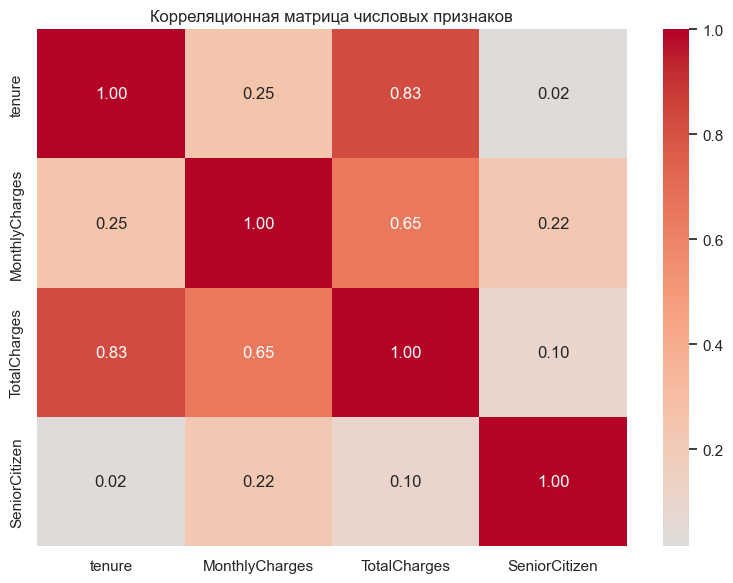

In [9]:
plt.figure(figsize=(8, 6))
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150)
plt.show()

## Корреляции:


## Итоговые выводы EDA

### Целевая переменная
- Ушло 1869 клиентов (26.6%), осталось 5163 (73.4%).
- **Классы несбалансированы** → при обучении использовать `class_weight='balanced'` и метрики F1, ROC-AUC (не accuracy).

### Сильнейшие факторы оттока
1. **Тип контракта** — Month-to-month 42.7% оттока vs Two year 2.85%. Разница в **15 раз**.
2. **Стаж (tenure)** — медиана у ушедших в ~3 раза ниже. Новые клиенты (0–12 мес) уходят в **5 раз** чаще «стариков».
3. **Способ оплаты** — Electronic check 45.3% vs Credit card 15.3% (в **3 раза**).
4. **PaperlessBilling** — Yes 33.6% vs No 16.4% (в **2 раза**).
5. **MonthlyCharges** — ушедшие платят больше (74 vs 61 в среднем).

### Распределения числовых признаков
- `tenure` — бимодальное (пики у 0 и ~70).
- `MonthlyCharges` — бимодальное (дешёвый сегмент ~20, дорогой ~80).
- `TotalCharges` — сильно скошено вправо (кумулятивная величина).
- Все признаки **не нормальны** → масштабирование обязательно, деревья подойдут лучше линейных моделей.

### Feature engineering для ML
- `tenure_bucket` — разбить tenure на группы (0–12, 13–24, 25–48, 49+).
- `avg_monthly = TotalCharges / tenure` — средний чек за всё время.
- Возможно `is_expensive = MonthlyCharges > 70` — отделить дорогой сегмент.
- `StandardScaler` для числовых, `OneHotEncoder` для категориальных.

### Гипотезы для модели
- Contract, tenure, MonthlyCharges — топ-3 признака.
- Взаимодействие «новый клиент + месячный контракт» → максимальный риск.
- LogisticRegression должна дать F1 > 0.75.

### Ограничения
- Данные из одного датасета (Kaggle Telco), возможно, не отражают все сегменты реального рынка.
- Классы несбалансированы — метрики на тесте надо интерпретировать с осторожностью.
